# MECHA, 8: the conductance of a root system

**What you will learn:** build a seedling's root system, every section with its own anatomy and all of them one
network; compute its **conductance** (how much water it takes up per unit of pull) and where along it the water
enters; then find two of MECHA's parameters from measurements of that conductance.

**You need:** tutorials 5 (experimental data) and 6 (along a root). **Run time:** about a minute.

**About the data.** `data/observed_krs.csv` is **synthetic**: `data/make_synthetic_data.py` made it from the model
itself, with known values of the parameters, and 3 % of noise. It stands for a measurement, so that you can check
what the fit finds.

## 1. A seedling's root system

`root_system` builds a main root and its laterals out of 5 mm segments. Each segment gets its own cross section (its
GRANAP anatomy) and its barrier stage, as in tutorial 6. The xylem vessels of all the sections are joined into one
network, up to the **collar**, where the root meets the stem.

Here: a main root of three segments (from the collar: one suberized, `3`, then two with a Casparian strip, `1`), and
a lateral of one segment branched on the main root's second segment.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.mecha.simulation import fit_root_system, root_system

SEEDLING = dict(main=(3, 1, 1), laterals=((1, (1,)),))
seedling = root_system(**SEEDLING)
seedling.sections

,axis,rank,barrier,radius,suf,uptake,kr
0,main,0,3,0.50,0.008781,0.001010,0.000002
1,main,1,1,0.50,0.330605,0.038023,0.000076
2,main,2,1,0.50,0.330307,0.037989,0.000076
3,lateral 1,0,1,0.25,0.330307,0.037989,0.000076


One row per section: its axis, its rank from the axis' base, its barrier, its radius (mm), its **suf** (see section
3), its water uptake (cm³ d⁻¹) and its kr (that of the section alone, as in tutorials 1–5).

## 2. Its conductance, Krs

The soil is at −1000 hPa all around the root, the collar's xylem at −5000 hPa. The water the whole root system takes
up is proportional to that difference of 4000 hPa. The proportionality factor is the **root system conductance**,
Krs, in cm³ hPa⁻¹ d⁻¹. It is what a pressure chamber measures on a whole root system, and what root architecture models
(MARSHAL, CPlantBox) use.

In [2]:
total = seedling.sections["uptake"].sum()
print(f"Krs = {seedling.conductance:.3e} cm3 hPa-1 d-1")
print(f"uptake {total:.3e} cm3 d-1 = Krs x 4000 hPa = {seedling.conductance * 4000:.3e}")

Krs = 2.875e-05 cm3 hPa-1 d-1
uptake 1.150e-01 cm3 d-1 = Krs x 4000 hPa = 1.150e-01


Krs depends on every section: on their anatomies, their barriers, the conductivities of their walls and membranes,
and their xylem.

## 3. Where the water enters

Each section's **standard uptake fraction** (SUF) is its share of the root system's uptake when the soil is the same
everywhere. The fractions add up to 1.

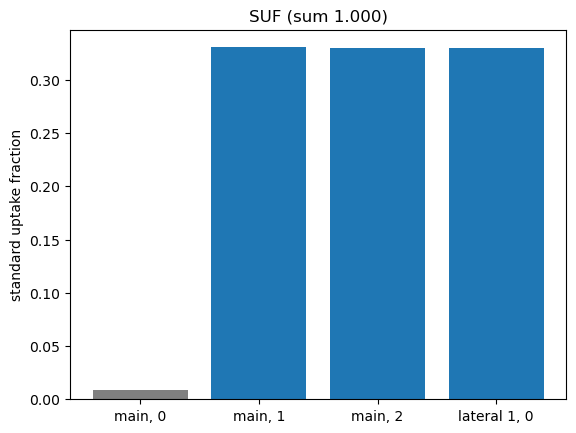

In [3]:
sections = seedling.sections
labels = [f"{axis}, {rank}" for axis, rank in zip(sections["axis"], sections["rank"])]
plt.bar(labels, sections["suf"], color=["grey" if b == 3 else "tab:blue" for b in sections["barrier"]])
plt.ylabel("standard uptake fraction"); plt.title(f"SUF (sum {sections['suf'].sum():.3f})");

The suberized section near the collar (grey) takes up almost nothing. The young sections take up the rest, the
lateral as much as a main root section with the same barrier and the same anatomy.

## 4. Two parameters from measured Krs

The water crosses the cells' membranes, partly through **aquaporins**, the membranes' water channels. MECHA has a
conductivity for each part: `kaqp` (the aquaporins) and `kmb` (the rest of the membrane). Both are hard to measure
on their own; Krs is measured on whole root systems.

`data/observed_krs.csv` holds Krs measured twice on the seedling: as it is (`control`), and with its aquaporins
inhibited (`inhibited`, e.g. with azide: their contribution divided by 10).

In [4]:
observed = pd.read_csv("data/observed_krs.csv")
observed

,variable,experiment,value,unit
0,root_system_conductance,control,0.000018,cm3 hPa-1 d-1
1,root_system_conductance,inhibited,0.000007,cm3 hPa-1 d-1


### With one measurement

`fit_root_system` searches the values of `kaqp` and `kmb` that make the model's Krs match the observations, within
their bounds (see `parameters()`). First with the control measurement alone, starting from two different points:

In [5]:
control = observed[observed["experiment"] == "control"]
fits = [fit_root_system(control, start=start, tolerance=1e-6, **SEEDLING)
        for start in ({}, {"kaqp": 1e-4, "kmb": 2e-4})]
for fit in fits:
    print({name: f"{value:.2e}" for name, value in fit.values.items()},
          f"model Krs {fit.compared['model'][0]:.3e}")

{'kaqp': '2.46e-04', 'kmb': '1.73e-05'} model Krs 1.850e-05
{'kaqp': '8.78e-05', 'kmb': '1.76e-04'} model Krs 1.850e-05


Both fits match the measured Krs, with **different** values: a lower `kaqp` with a higher `kmb` gives the same Krs.
One measurement cannot tell the two paths apart. Any pair along a line of the (kaqp, kmb) plane fits.

### With two measurements

The inhibited measurement tells them apart: blocking the aquaporins lowers Krs a lot if the water goes mostly through
them, little if it goes through the rest of the membranes.

In [6]:
fit = fit_root_system(observed, tolerance=1e-6, **SEEDLING)
print({name: f"{value:.2e}" for name, value in fit.values.items()})
fit.compared[["experiment", "value", "model"]]

{'kaqp': '2.01e-04', 'kmb': '6.23e-05'}


,experiment,value,model
0,control,0.000018,0.000019
1,inhibited,0.000007,0.000007


The fit finds `kaqp` ≈ 2.0e-4 and `kmb` ≈ 6.2e-5 cm hPa⁻¹ d⁻¹; the data were made with 2e-4 and 6e-5. The
remaining difference is the noise.

**Not every parameter can be found this way.** The cell walls' conductivity, `kw`, matters less: a 10 % change of
`kw` changes Krs by about 2 %, and by less than 0.5 % with the aquaporins inhibited. With a Casparian strip, the walls
carry the water only up to the endodermis. Krs measurements constrain it poorly; a measurement on a root without
barriers, or of another quantity, would help.

## Try it yourself

1. Add 10 % of noise to the observations: how far do the fitted values move?
2. Fit `kw` and `kaqp` with both measurements. What happens to `kw`?
3. Change the seedling (more laterals, more suberized sections) and look at the SUF.

**Going further:** developer tutorial 10 shows how Krs is declared and computed in metafspm, and how the calibration
compares the model with the observations.